# 02 — Baselines and the offshore capacity correction (step 1)

**Question.** How good are the three reference forecasts, and how much does the offshore capacity correction
(step 1) add on its own?

The three baselines are runs 001–003 of the 20-run budget in `experiments/log.csv`:

| run | forecast (P50 anchor) | uncertainty |
|---|---|---|
| `001_persistence` | actual total at 09:00 UTC on D−1, carried to all hours of D | empirical quantiles of its errors over the last 90 training days |
| `002_vendor_raw` | vendor DA total `da_total` | empirical error quantiles over the last 90 training days, in 5 forecast-level bins |
| `003_vendor_capacity` | step-1 corrected DA total `da_total_adj` | same as 002 |

Step 1 scales the vendor DA offshore forecast by `r = Σ actual_off / Σ cur_off` over the 30 days up to the
issue-time cutoff (hours with `cur_off` > 100 MWh); onshore is unchanged (`windfc.capacity`).

All runs are scored by the frozen `windfc.evaluate` on the same 8,580 validation hours (4 folds, delivery days
2025-05-01 → 2026-04-30), refitting before each fold on all earlier data. CRPS is the mean pinball loss over the 9
quantiles (MWh); bias is mean(P50 − actual). Only delivery days before 2026-05-01 are used.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from windfc.cutoff import delivery_day
from windfc.evaluate import TEST_PERIOD
from windfc.notebook import load_validation
from windfc.run import REPO_ROOT as ROOT

TEST_START = pd.Timestamp(TEST_PERIOD[0])
FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
# Fixed series colours (validated categorical slots 1-3, then neutral ink).
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "grey": "#8a8984"}

# Validation-only data (windfc.notebook.load_validation): hours whose Danish local
# delivery day is before the locked test period; test rows are filtered while reading.
df = load_validation()
dday = delivery_day(df.index)
assert dday.max() < TEST_START  # also asserted inside load_validation
print(f"hours {df.index.min()} .. {df.index.max()} UTC; delivery days {dday.min().date()} .. {dday.max().date()}")

hours 2021-12-31 23:00:00 .. 2026-04-30 21:00:00 UTC; delivery days 2022-01-01 .. 2026-04-30


In [2]:
from windfc.notebook import fold_table, rerun
from windfc.run import read_log

LOG = ROOT / "experiments" / "log.csv"
CONFIGS = ROOT / "experiments" / "configs"
log = read_log(LOG)  # read only; rerun() writes to a temp log and refuses this path

## 1. The logged rows

In [3]:
cols = ["run_id", "git_hash", "crps_f1", "crps_f2", "crps_f3", "crps_f4", "crps_mean",
        "mae_p50_mean", "coverage_mean", "bias_mean", "n_hours", "decision"]
base_log = log[log.run_id.isin(["001_persistence", "002_vendor_raw", "003_vendor_capacity"])][cols]
base_log.assign(git_hash=base_log.git_hash.str[:7]).set_index("run_id").round(3)

,git_hash,crps_f1,crps_f2,crps_f3,crps_f4,crps_mean,mae_p50_mean,coverage_mean,bias_mean,n_hours,decision
run_id,,,,,,,,,,,
001_persistence,fd7e289,347.252,366.117,513.364,424.288,412.755,1068.248,0.792,-28.319,8580,baseline
002_vendor_raw,d63b83f,122.905,122.281,130.880,100.825,119.223,299.586,0.773,-4.294,8580,baseline
003_vendor_capacity,ace8362,124.344,123.041,132.508,103.050,120.736,303.013,0.778,15.298,8580,baseline


## 2. Per-fold results

The log keeps fold-level CRPS only, so the configs are re-run here into a throwaway log (the real log is not
written). `rerun` asserts that each re-run reproduces the logged mean CRPS.

In [4]:
base = {rid: rerun(CONFIGS / f"{rid}.yaml") for rid in ["001_persistence", "002_vendor_raw", "003_vendor_capacity"]}
ft = fold_table(base.values())
folds = pd.DataFrame(base["002_vendor_raw"]["folds"])[["fold", "start", "end", "n_hours"]].set_index("fold")
folds

,start,end,n_hours
fold,,,
1,2025-05-01,2025-07-31,2208
2,2025-08-01,2025-10-31,2131
3,2025-11-01,2026-01-31,2106
4,2026-02-01,2026-04-30,2135


In [5]:
means = ft.groupby("run").mean(numeric_only=True).assign(fold="mean")
means["n_hours"] = ft.groupby("run").n_hours.sum()
tab = pd.concat([ft, means.reset_index()]).set_index(["run", "fold"]).sort_index(level=0, sort_remaining=False)
tab.round(3)

crps   mae_p50  coverage_80     bias  crps_norm  n_hours
run                 fold                                                             
001_persistence     1     347.252   911.947        0.879    4.075      0.250     2208
                    2     366.117   952.831        0.779  -47.152      0.222     2131
                    3     513.364  1306.790        0.668   23.310      0.228     2106
                    4     424.288  1101.424        0.840  -93.508      0.222     2135
                    mean  412.755  1068.248        0.792  -28.319      0.231     8580
002_vendor_raw      1     122.905   309.973        0.769  146.588      0.089     2208
                    2     122.281   312.847        0.795   -4.074      0.074     2131
                    3     130.880   323.205        0.726 -173.626      0.058     2106
                    4     100.825   252.319        0.801   13.936      0.053     2135
                    mean  119.223   299.586        0.773   -4.294      0.068     8580
003_vendor_capacity 1     124.344   310.505        0.769  146.415      0.090     2208
                    2     123.041   312.840        0.815   36.074      0.075     2131
                    3     132.508   328.958        0.741 -171.831      0.059     2106
                    4     103.050   259.750        0.787   50.534      0.054     2135
                    mean  120.736   303.013        0.778   15.298      0.069     8580

**Reading.** Persistence is far behind (mean CRPS 413 vs 119 MWh): at 13–37 h after the last known hour (12–36 h after
issue time, for the hours of a local delivery day) the last observation
carries little information, which confirms that the vendor DA is the right anchor. Both vendor baselines have
P10–P90 coverage of 73–82% per fold (mean 77–78%, inside the 76–84% guardrail). Their mean P50 bias is small
(−4 and +15 MWh) only because folds cancel: per fold it ranges from about −174 MWh (fold 3, Nov–Jan) to +147 MWh
(fold 1, May–Jul) for both vendor baselines. A likely reason (hypothesis 1 in section 6, untested) is that the 90-day
error offsets carry the bias of the preceding season into the next one: after a winter with large negative vendor
bias, fold 1 is over-lifted; after a lower-bias Aug–Oct, fold 3 is under-lifted. Fold 2 does not fit cleanly:
there the P50 bias is −4 MWh for 002 but +36 MWh for 003, which the lag story alone does not predict.

**Run hypotheses.** 002's hypothesis held in part: it beats persistence by a wide margin, and the raw DA point
forecast is strongly negatively biased (−137 to −484 MWh per fold, section 5), but the probabilistic baseline's
P50 is not (−4 MWh on average, −174 to +147 per fold) consistent with the error offsets re-centring it.

## 3. Gain from step 1 alone (003 vs 002)

In [6]:
g = ft.pivot(index="fold", columns="run", values="crps")
gain = pd.DataFrame({
    "CRPS raw (002)": g["002_vendor_raw"],
    "CRPS capacity (003)": g["003_vendor_capacity"],
})
gain["change %"] = 100 * (gain["CRPS capacity (003)"] / gain["CRPS raw (002)"] - 1)
gain.loc["mean"] = gain.mean()
gain.loc["mean", "change %"] = 100 * (gain.loc["mean", "CRPS capacity (003)"] / gain.loc["mean", "CRPS raw (002)"] - 1)
gain.round(2)

,CRPS raw (002),CRPS capacity (003),change %
fold,,,
1,122.91,124.34,1.17
2,122.28,123.04,0.62
3,130.88,132.51,1.24
4,100.82,103.05,2.21
mean,119.22,120.74,1.27


**Result: step 1 alone does not help.** The capacity-corrected vendor scores slightly *worse* than the raw vendor
on all four folds (+0.6% to +2.2% CRPS; +1.3% on the mean), and its mean P50 MAE is also slightly worse (303.0 vs 299.6 MWh). Its run
hypothesis ("removes most of the negative bias and lowers CRPS versus the raw vendor on most folds") is therefore
rejected by the data. The sections below look for the reason.

## 4. The capacity ratio over time

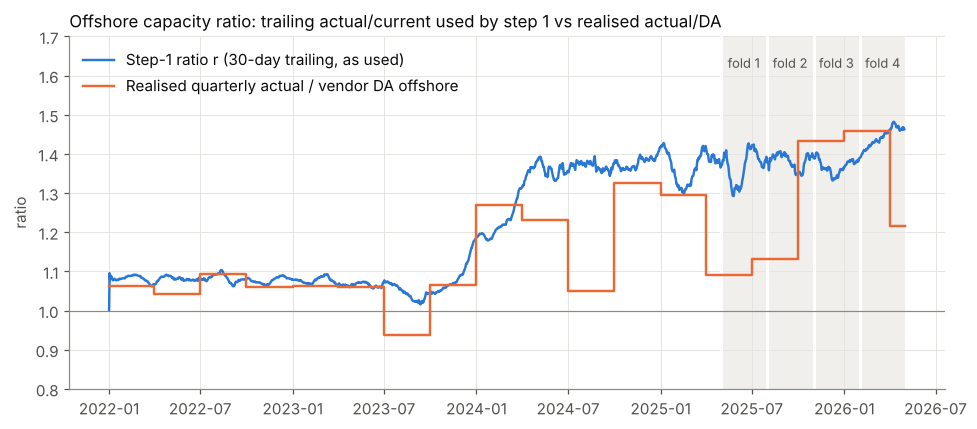

In [7]:
from windfc.capacity import capacity_ratio

days = pd.date_range(dday.min(), dday.max(), freq="D")
ratio = capacity_ratio(df, days)
qtr = df.groupby(dday.to_period("Q"))
realised = pd.DataFrame({
    "actual / vendor current": qtr.actual_off.sum() / qtr.cur_off.sum(),
    "actual / vendor DA": qtr.actual_off.sum() / qtr.da_off.sum(),
})
realised.index = realised.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4))
for _, f in folds.iterrows():
    ax.axvspan(pd.Timestamp(f.start), pd.Timestamp(f.end) + pd.Timedelta(days=1), color="#f0efec", lw=0)
    ax.axvline(pd.Timestamp(f.start), color="white", lw=2)
ax.plot(ratio.index, ratio.values, color=C["blue"], label="Step-1 ratio r (30-day trailing, as used)")
steps = pd.concat([realised["actual / vendor DA"],
                   pd.Series([realised["actual / vendor DA"].iloc[-1]], index=[dday.max() + pd.Timedelta(days=1)])])
ax.step(steps.index, steps.values, where="post", color=C["orange"],
        label="Realised quarterly actual / vendor DA offshore")
ax.axhline(1, color=C["grey"], lw=0.8)
for i, f in folds.iterrows():
    ax.text(pd.Timestamp(f.start) + pd.Timedelta(days=45), 1.62, f"fold {i}", ha="center", fontsize=8.5, color="#52514e")
ax.set_ylim(0.8, 1.7)
ax.set_ylabel("ratio")
ax.set_title("Offshore capacity ratio: trailing actual/current used by step 1 vs realised actual/DA",
             loc="left", fontsize=11)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
# Last row (2026-04-01) covers April 2026 only.
realised.assign(**{"vendor DA / vendor current": realised["actual / vendor current"] / realised["actual / vendor DA"]}).round(3)

,actual / vendor current,actual / vendor DA,vendor DA / vendor current
hour_utc,,,
2022-01-01,1.082,1.062,1.018
2022-04-01,1.083,1.041,1.040
2022-07-01,1.084,1.094,0.991
2022-10-01,1.079,1.061,1.017
2023-01-01,1.076,1.062,1.013
2023-04-01,1.069,1.059,1.009
2023-07-01,1.043,0.937,1.113
2023-10-01,1.111,1.066,1.042
2024-01-01,1.241,1.270,0.977


**Reading.** The ratio is about 1.08 through 2023, jumps to about 1.35–1.40 during 2024 when new offshore capacity
appears, and drifts to about 1.47 by April 2026. It is estimated against the vendor's **current** offshore forecast
but applied to the vendor's **day-ahead** offshore forecast, and those two vendor series are not the same size:
from 2024 the DA offshore forecast is 15–31% *higher* than the current forecast in the summer quarters (Q2–Q3) and
about equal in winter. In summer the correction therefore over-scales the DA offshore forecast (realised
actual/DA is about 1.05–1.23 there, versus r ≈ 1.3–1.42).

## 5. Point bias before and after step 1, per fold

Point forecasts only (no error model), all valid hours of each fold, mean (forecast − actual) in MWh:

In [9]:
from windfc.capacity import apply_capacity_correction
from windfc.evaluate import period_mask

adj = apply_capacity_correction(df, ratio)
rows = []
for i, f in folds.iterrows():
    msk = period_mask(adj.index, f.start, f.end)
    a = adj[msk].dropna(subset=["da_total", "da_total_adj", "actual_total"])
    rows.append({"fold": i,
                 "offshore bias raw": (a.da_off - a.actual_off).mean(),
                 "offshore bias corrected": (a.da_off_adj - a.actual_off).mean(),
                 "total bias raw": (a.da_total - a.actual_total).mean(),
                 "total bias corrected": (a.da_total_adj - a.actual_total).mean(),
                 "total MAE raw": (a.da_total - a.actual_total).abs().mean(),
                 "total MAE corrected": (a.da_total_adj - a.actual_total).abs().mean()})
pd.DataFrame(rows).set_index("fold").round(1)

,offshore bias raw,offshore bias corrected,total bias raw,total bias corrected,total MAE raw,total MAE corrected
fold,,,,,,
1,-33.2,153.4,-136.7,49.9,332.3,311.1
2,-121.1,109.1,-199.8,30.4,380.8,330.0
3,-299.4,-45.6,-484.4,-230.5,566.6,413.3
4,-212.9,42.8,-379.7,-124.0,483.2,354.9


**Reading.** As a *point* forecast, step 1 does what it was designed for: on every fold it reduces the total DA
bias and the MAE (by 6% in fold 1, 13% in fold 2 and 26–27% in folds 3–4). In folds 1 and 2 (May–Oct) it over-corrects offshore
(offshore bias turns +109 to +153 MWh), consistent with the summer DA/current mismatch above.

## 6. Why the corrected baseline still scores worse — hypotheses, not established facts

1. **The error model already does most of step 1's job.** Both vendor baselines add empirical quantiles of the
   last 90 days of errors to their anchor, which removes the average bias of those 90 days. A capacity gap that is
   stable over months is therefore already absorbed into the offsets of the raw baseline; the large point-forecast
   gain of step 1 (section 5) is largely duplicated. What remains after the offsets is a fold-level bias of similar
   size for 002 and 003 (section 2), i.e. a seasonal bias the trailing 90-day offset lags — step 1 does not touch it.
2. **The ratio adds day-to-day noise.** A 30-day trailing ratio moves with the weather mix of the last month
   (e.g. curtailment, which hours exceed the 100 MWh threshold). That variation is passed to the forecast but is
   not information about the delivery day, which widens the error distribution slightly.
3. **The ratio is calibrated to the wrong vendor series.** It is estimated against `cur_off` and applied to
   `da_off`, whose relationship to `cur_off` is seasonal (section 4). This explains the offshore over-correction
   in folds 1–2.
4. **Capacity step-ups lag by up to 30 days.** This is a known weakness of step 1, but the large step (2024)
   happened before the validation folds, so it is unlikely to explain the validation result.

These are consistent with the data shown but were not tested separately; any test would cost runs from the
budget or require changing the step-1 definition, which is fixed for v1.

## Summary

- Persistence (CRPS 413 MWh) is a floor; the raw vendor with empirical error quantiles (CRPS 119.2 MWh, coverage 77%) is the real benchmark.
- Step 1 alone **does not improve** the probabilistic baseline: CRPS +1.3% on average, worse on all four folds — even though, as a point forecast, it cuts DA MAE by 6–27% per fold. This is likely because the empirical error offsets already remove most of the bias it targets (hypothesis 1, untested; fold 2 does not fit it cleanly).
- The largest remaining baseline error is a fold-level P50 bias (−174 to +147 MWh), plausibly a seasonal bias that the trailing 90-day offset lags (untested); this is what a model with recent-error features (notebook 03) can address.
- Consequence for the project: the planned split of the final gain into a "coverage" part (002 → 003) and a "skill" part (003 → model) does not hold as originally framed — on validation the coverage part is slightly negative. The model (notebook 03) is compared against both baselines.
- The corrected features (`da_off_adj`, `da_total_adj`) remain inputs to the models in notebook 03; whether they beat raw vendor inputs inside a model is a separate question.